# Example of the aitlas toolbox in the context of multi class image classification

The COWC dataset can be used for image classification and object detection. This notebook showcases an image classification example.

## Import the required packages

In [ ]:
from aitlas.datasets import COWCImageClassificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/cowc_image_classification/datasets/patch_sets/detection/",
    "csv_file": "./data/cowc_image_classification/datasets/patch_sets/detection/COWC_train_list_detection.txt",
}
dataset = COWCImageClassificationDataset(dataset_config)
print(f"Total number of patches: {len(dataset)}")

Total number of patches: 308988


## Show images from the dataset

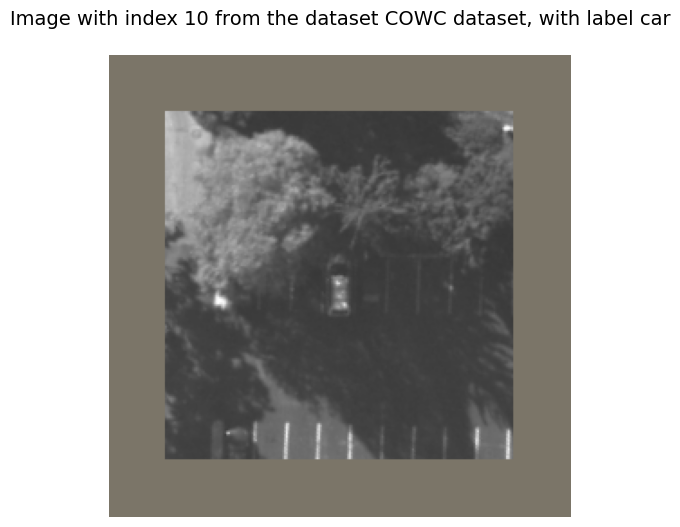

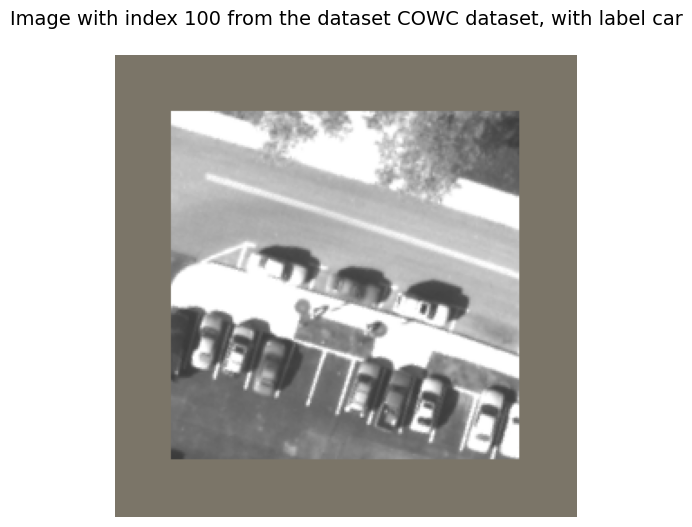

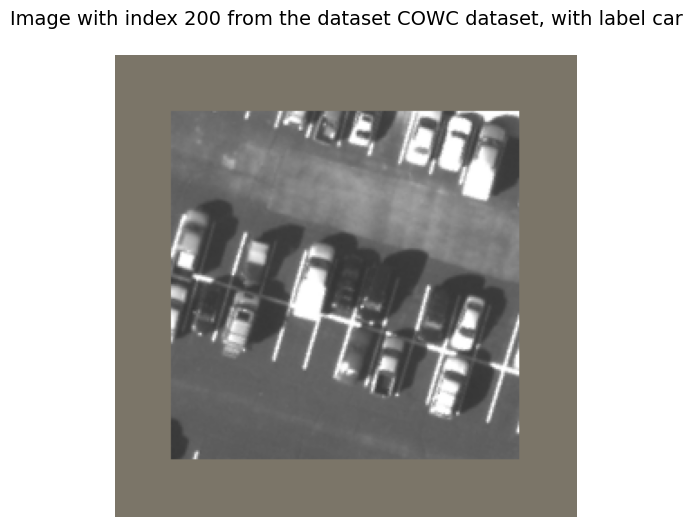

In [28]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200);

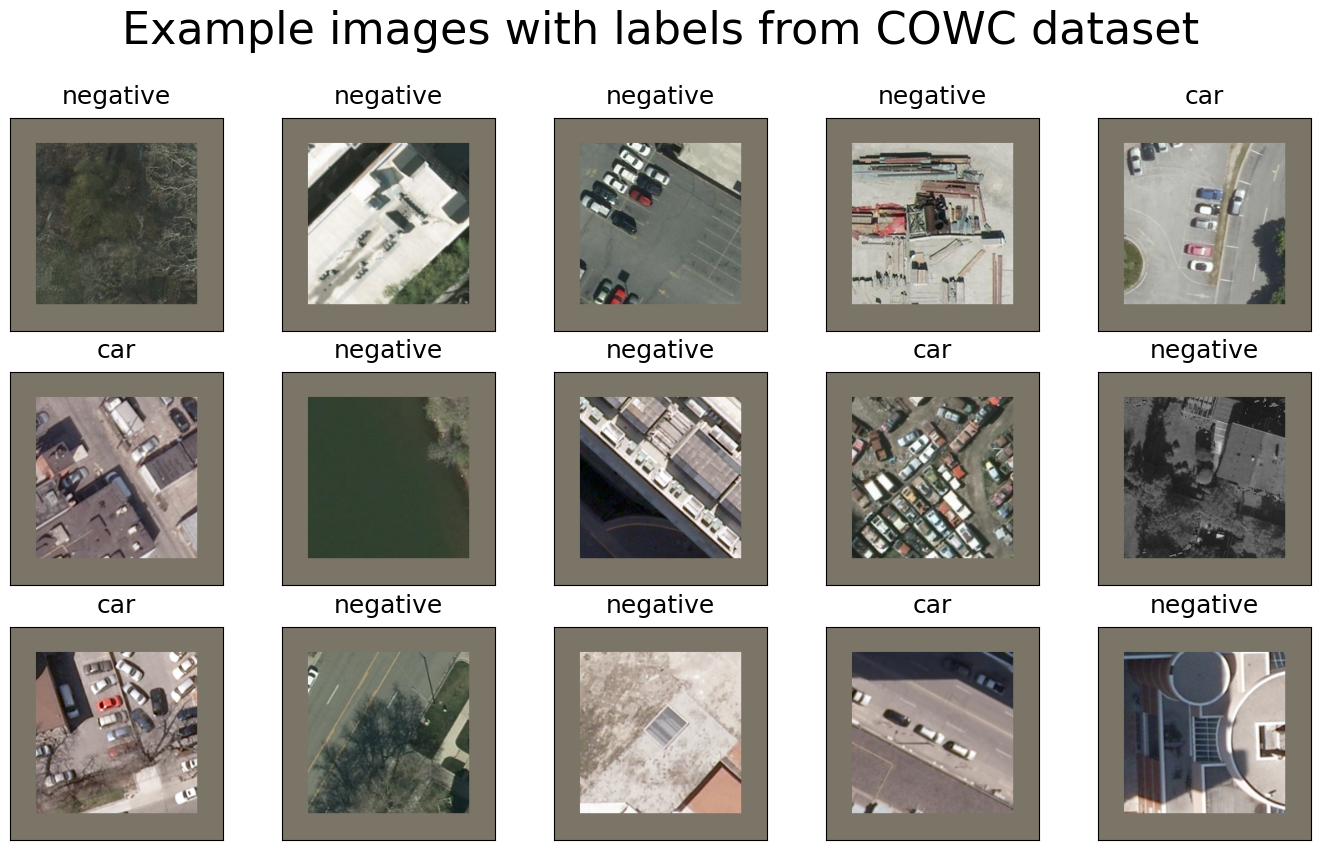

In [29]:
fig4 = dataset.show_batch(15);

## Inspect the data

In [57]:
dataset.show_samples()

,File_name,Label
0,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
1,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
2,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
3,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
4,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
5,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
6,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
7,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
8,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1
9,Columbus_CSUAV_AFRL/train/car.Columbus_EO_Run0...,1


In [68]:
dataset.data_distribution_table()

,Label,Count
0,Negative,200204
1,Car,108784


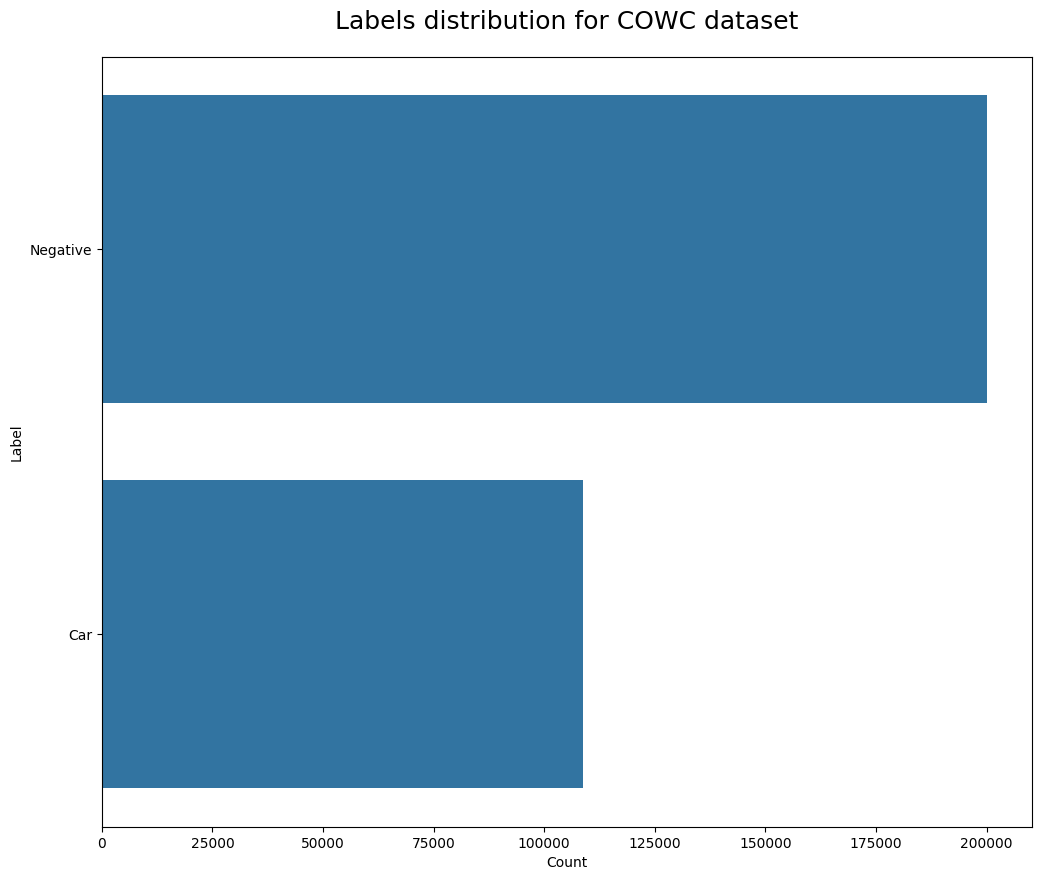

In [69]:
fig = dataset.data_distribution_barchart();

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/cowc_image_classification/datasets/patch_sets/detection/",
    "csv_file": "./data/cowc_image_classification/datasets/patch_sets/detection/COWC_train_list_detection.txt",
}

train_dataset = COWCImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/cowc_image_classification/datasets/patch_sets/detection/",
    "csv_file": "./data/cowc_image_classification/datasets/patch_sets/detection/COWC_test_list_detection.txt",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = COWCImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(308988, 79447)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/COWC_image_classification/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-10-08 09:15:10,523 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-10-08 09:15:10,728 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [10]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-10-08 09:15:12,338 INFO Starting training.
training: 100%|██████████| 9656/9656 [40:24<00:00,  3.98it/s]
2025-10-08 09:55:36,939 INFO epoch: 1, time: 2424, loss:  0.11825
testing on train set: 100%|██████████| 9656/9656 [14:43<00:00, 10.93it/s]
2025-10-08 10:10:22,920 INFO Accuracy:0.943819824718112, Precision Micro:0.943819824718112, Precision Macro:0.9572530031521125, Precision Weighted:0.9472529936050518, Precision per Class:[0.92345424 0.99105177], Recall Micro:0.943819824718112, Recall Macro:0.9219617605353614, Recall Weighted:0.943819824718112, Recall per Class:[0.99583924 0.84808428], F1_score Micro:0.9438198247181114, F1_score Macro:0.9361464544163602, F1_score Weighted:0.9426956082350945, F1_score per Class:[0.95828176 0.91401115]
testing on validation set: 100%|██████████| 2483/2483 [03:44<00:00, 11.07it/s]
2025-10-08 10:14:07,196 INFO Accuracy:0.9552657746673883, Precision Micro:0.9552657746673883, Precision Macro:0.9636767804111497, Precision Weighted:0.957268822029951

0.03927633947156807

## Predictions

2025-10-09 06:43:14,300 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/COWC_image_classification/checkpoint.pth.tar
2025-10-09 06:43:14,689 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/COWC_image_classification/checkpoint.pth.tar at epoch 11


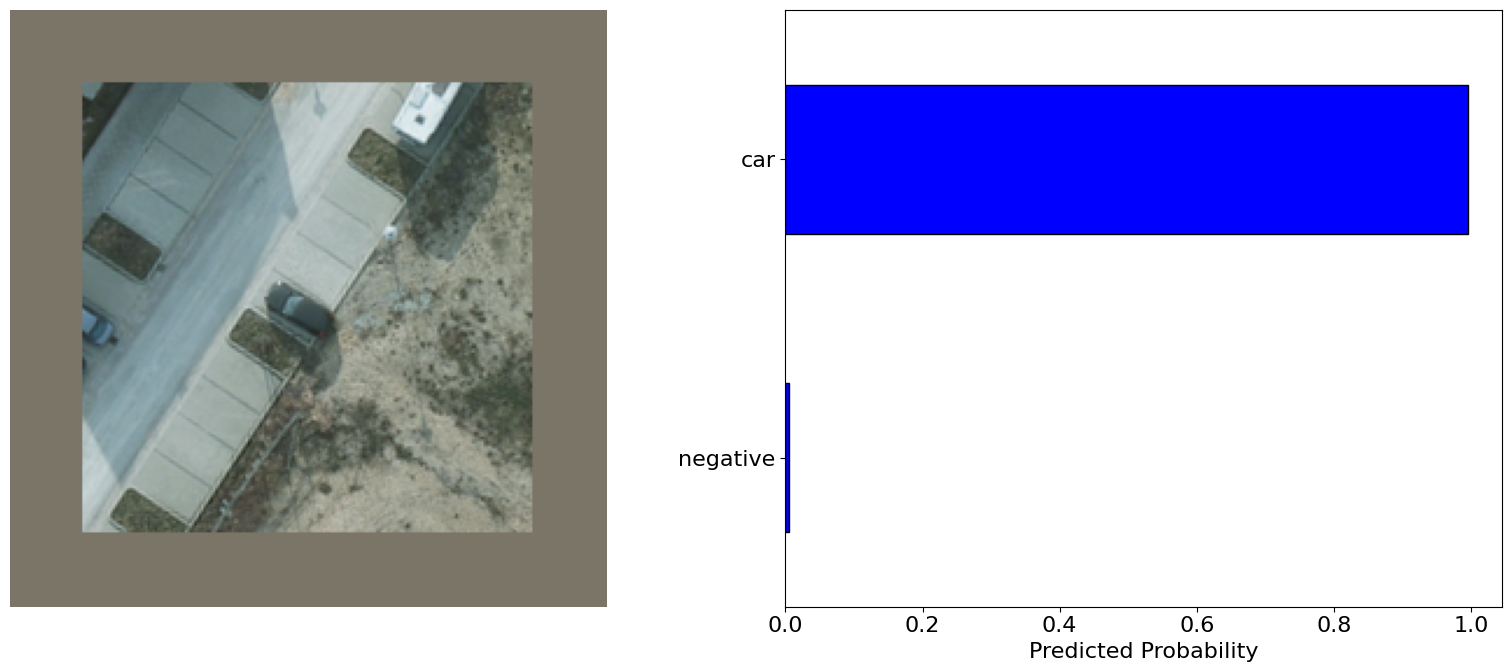

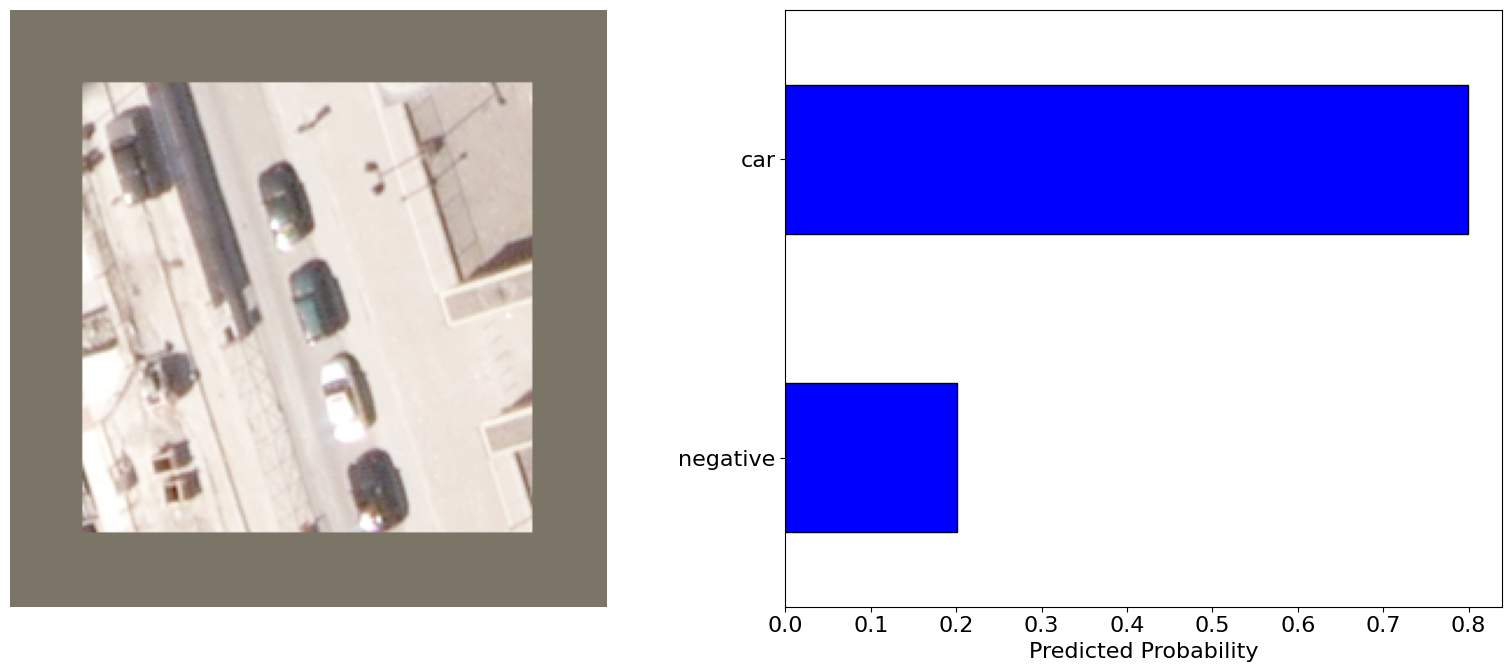

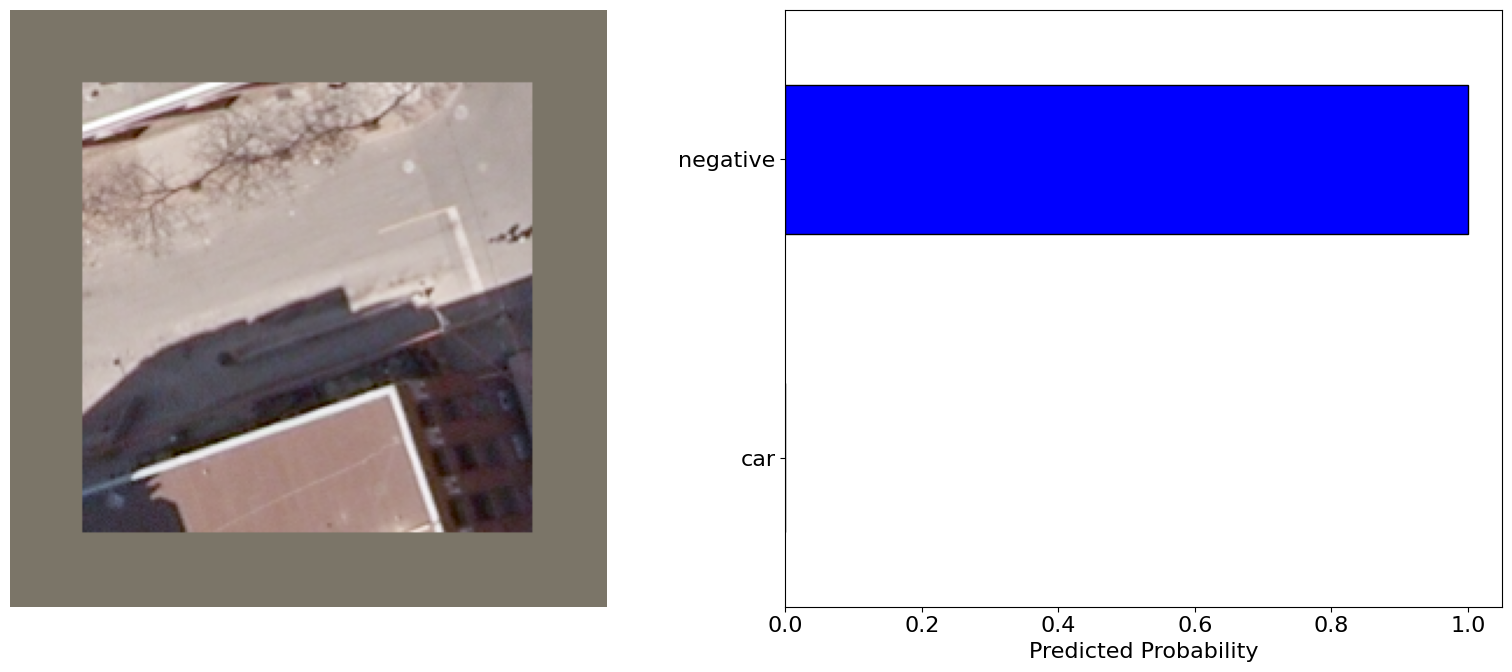

In [ ]:
labels = ["negative","car"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/COWC_image_classification/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/cowc_image_classification/datasets/patch_sets/detection/Potsdam_ISPRS/test/car.Potsdam_2_10_RGB.00767.00931.105.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/cowc_image_classification/datasets/patch_sets/detection/Toronto_ISPRS/test/car.Toronto_03553.00359.06676.000.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/cowc_image_classification/datasets/patch_sets/detection/Toronto_ISPRS/test/neg.Toronto_03559.00561.04609.000.png')
fig = model.predict_image(image, labels, transform)